# Solving nonlinear fracture equations

Nonlinear fracture calculations using dimensionless example parameters.

## Fracture relation

$$\pi a\sigma_f^2\left[1+H\left(\frac{\sigma_f}{\sigma_R}\right)^m\right]-K^2=0,\qquad H=\frac{2\alpha(m+1)}{m+2}.$$

$a$ is the crack half-length, $K$ the toughness parameter and $\sigma_R$ the reference stress. $\alpha$ and $m$ describe the nonlinear term.

With $\ell=K^2/(\pi\sigma_R^2)$, $\xi=a/\ell$, $s=\sigma_f/\sigma_R$ and $\hat q=q/\ell$:

$$\left(\xi+\frac{\hat q}{2}\right)s^2(1+Hs^m)-1=0.$$

NLFM uses $\hat q=0$; NLFM + QFM includes the crack increment.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#233744", "text.color": "#233744",
    "axes.edgecolor": "#9aabb2", "figure.facecolor": "white",
    "savefig.facecolor": "white", "svg.fonttype": "none",
})
colors = ["#236b73", "#bb7639", "#5d6eaa"]
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

from scipy.optimize import brentq

alpha, m = 1.0, 2.0
q_hat = 0.6
xi = np.geomspace(0.06, 25, 160)

In [2]:
def fracture_strength(xi, q_hat=0.0, alpha=1.0, m=2.0):
    xi = np.atleast_1d(np.asarray(xi, dtype=float))
    if np.any(xi <= 0) or q_hat < 0 or alpha < 0 or m <= 0:
        raise ValueError("Lengths and exponent must be positive; q and alpha must be nonnegative")
    H = 2 * alpha * (m + 1) / (m + 2)
    roots = []
    for x in xi:
        length = x + q_hat / 2
        def residual(s):
            return length * s**2 * (1 + H * s**m) - 1
        upper = 2 / np.sqrt(length)
        roots.append(brentq(residual, 0, upper, xtol=1e-13))
    return np.asarray(roots)

nlfm = fracture_strength(xi, alpha=alpha, m=m)
quantized = fracture_strength(xi, q_hat=q_hat, alpha=alpha, m=m)
reduction = 100 * (nlfm - quantized) / nlfm

## Calculated curves

A comparison using dimensionless example parameters.

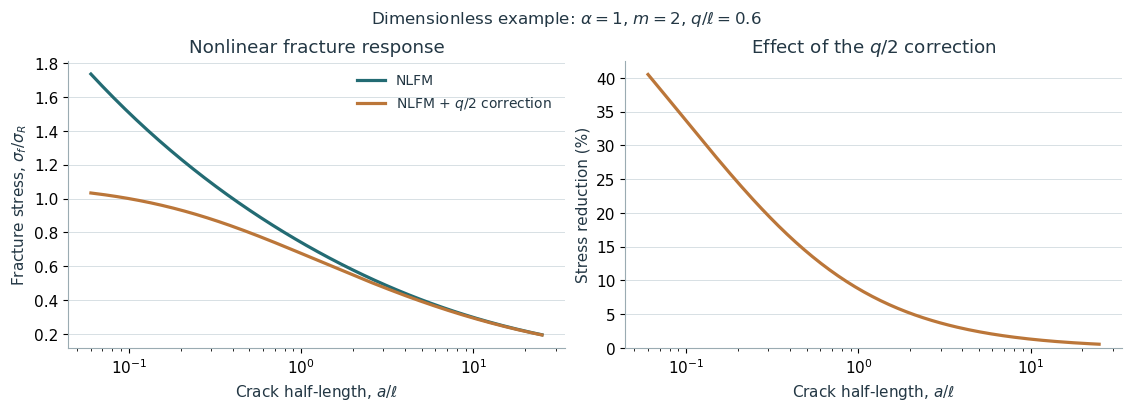

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.0), layout="constrained")
ax[0].semilogx(xi, nlfm, color=colors[0], lw=2.3, label="NLFM")
ax[0].semilogx(xi, quantized, color=colors[1], lw=2.3,
               label=r"NLFM + $q/2$ correction")
ax[0].set(xlabel=r"Crack half-length, $a/\ell$", ylabel=r"Fracture stress, $\sigma_f/\sigma_R$",
          title="Nonlinear fracture response")
ax[0].legend(frameon=False, fontsize=10)
ax[1].semilogx(xi, reduction, color=colors[1], lw=2.3)
ax[1].set(xlabel=r"Crack half-length, $a/\ell$", ylabel="Stress reduction (%)",
          title=r"Effect of the $q/2$ correction", ylim=(0, None))
for a in ax:
    a.grid(axis="y", color="#d7e0e4", lw=0.7)
fig.suptitle(r"Dimensionless example: $\alpha=1$, $m=2$, $q/\ell=0.6$", fontsize=12)
fig.savefig("figures/nonlinear_fracture.png", dpi=180, bbox_inches="tight")
fig.savefig("figures/nonlinear_fracture.svg", bbox_inches="tight")
plt.show()

## Numerical roots

In [4]:
selected = np.array([0.1, 1.0, 10.0])
H = 2 * alpha * (m + 1) / (m + 2)
rows = []
for q, label in [(0.0, "NLFM"), (q_hat, "NLFM + q/2")]:
    roots = fracture_strength(selected, q_hat=q, alpha=alpha, m=m)
    residual = (selected + q / 2) * roots**2 * (1 + H * roots**m) - 1
    rows.extend({"model": label, "a/ell": x, "stress/sigma_R": s, "abs_residual": abs(r)}
                for x, s, r in zip(selected, roots, residual))
root_table = pd.DataFrame(rows)
display(root_table.style.hide(axis="index").format({"a/ell": "{:.1f}",
        "stress/sigma_R": "{:.5f}", "abs_residual": "{:.1e}"}))
root_table.to_csv("results/fracture_roots.csv", index=False)

model,a/ell,stress/sigma_R,abs_residual
NLFM,0.1,1.50668,1.1e-16
NLFM,1.0,0.74066,3.3e-16
NLFM,10.0,0.29716,4.4e-16
NLFM + q/2,0.1,1.00000,2.0e-15
NLFM + q/2,1.0,0.67569,6.2e-14
NLFM + q/2,10.0,0.29325,2.2e-16
